In [7]:
import os
import pandas as pd
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

In [8]:

nltk.download('stopwords')


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\dbda.STUDENTSDC\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [9]:
dataset = pd.read_csv("D:\Machine Learning\Datasets\Restaurant_Reviews.tsv", sep='\t')
dataset.head()

,Review,Liked
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1


In [10]:
dataset['Review']

0                               Wow... Loved this place.
1                                     Crust is not good.
2              Not tasty and the texture was just nasty.
3      Stopped by during the late May bank holiday of...
4      The selection on the menu was great and so wer...
                             ...                        
995                             Appetite instantly gone.
996    Overall I was not impressed and would not go b...
997    The whole experience was underwhelming, and I ...
998    Then, as if I hadn't wasted enough of my life ...
999                                   The food was good.
Name: Review, Length: 1000, dtype: object

In [11]:
corpus = []
stops = stopwords.words('english')
for i in range(0,dataset.shape[0]):
    review = re.sub('[^a-zA-Z]','',dataset['Review'][i])
    review = review.lower()
    review = review.split()
    ps = PorterStemmer()
    review = [ps.stem(word) for word in review if not word in set(stops)]
    review = ' '.join(review)
    corpus.append(review)

corpus[:5]

['wowlovedthisplac',
 'crustisnotgood',
 'nottastyandthetexturewasjustnasti',
 'stoppedbyduringthelatemaybankholidayoffricksteverecommendationandlovedit',
 'theselectiononthemenuwasgreatandsowerethepric']

### Count Vectorization

In [35]:
cv = CountVectorizer(max_features = 800)
X = cv.fit_transform(corpus).toarray()
X = pd.DataFrame(X, columns=cv.get_feature_names_out())
y = dataset['Liked']

In [36]:
X.head()

,adrivethrumeansyoudonotwanttowaitaroundforhalfanhourforyourfoodbutsomehowwhenweendupgoingheretheymakeuswaitandwait,afantasticneighborhoodgem,aflywasinmyapplejuiceafli,afteralltheravereviewsicouldntwaittoeatherewhatadisappoint,afteripulledupmycariwaitedforanotherminutesbeforebeingacknowledg,afterminuteswaitigotat,afteronebiteiwashook,afterthedisappointingdinnerwewentelsewherefordessert,aftertwoifeltdisgust,afterwaitinganhourandbeingseatediwasnotinthegreatestofmood,...,wouldcomebackagainifihadasushicravingwhileinvega,wouldnotgoback,wouldnotrecommendtooth,wowlovedthisplac,wowveryspicybutdelici,youcantbeatthat,youcantgowrongwithanyofthefoodher,youcanwatchthempreparingthedeliciousfood,yougetincrediblyfreshfishpreparedwithcar,yourserverssuckwaitcorrectionourserverheimersuck
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [37]:
X.shape

(1000, 800)

In [38]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state= 25, stratify= y )
classifier = RandomForestClassifier(random_state= 25, n_estimators= 25)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)
print(accuracy_score(y_test,y_pred))

0.51


In [39]:
classifier = LogisticRegression()
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)
print(accuracy_score(y_test, y_pred))

0.51


### TF-IDF Vectorization

In [40]:
cv = TfidfVectorizer(max_features=800)
X = cv.fit_transform(corpus).toarray()
X = pd.DataFrame(X,columns=cv.get_feature_names_out())
y = dataset['Liked']

In [41]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state= 25, stratify= y )
classifier = RandomForestClassifier(random_state= 25, n_estimators= 25)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)
print(accuracy_score(y_test,y_pred))

0.51


In [42]:
classifier = LogisticRegression()
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)
print(accuracy_score(y_test, y_pred))

0.51


In [43]:
import os
# os.chdir("D:\\meridianthe4\\PML\\Datasets")
import pandas as pd
import re
import nltk 
nltk.download('stopwords')
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
# dataset = pd.read_csv("Restaurant_Reviews.tsv", sep='\t')
dataset.head()
corpus = []
stops = stopwords.words('english')
for i in range(0, dataset.shape[0]):
    review = re.sub('[^a-zA-Z]', ' ', dataset['Review'][i])
    review = review.lower()
    review = review.split()
    ps = PorterStemmer()
    review = [ps.stem(word) for word in review if not word in set(stops)]
    review = ' '.join(review)
    corpus.append(review)
corpus[:5]
### Count Vectorization
cv = CountVectorizer(max_features=800)
X = cv.fit_transform(corpus).toarray()
X = pd.DataFrame(X, columns=cv.get_feature_names_out())
y = dataset['Liked']
X.head()
classifier = LogisticRegression()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=25, stratify=y)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)
print("Accuracy: ", accuracy_score(y_test, y_pred))

### TF-IDF Vectorization
cv = TfidfVectorizer(max_features=800)
X = cv.fit_transform(corpus).toarray()
X = pd.DataFrame(X, columns=cv.get_feature_names_out())
y = dataset['Liked']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=25, stratify=y)
classifier = RandomForestClassifier(n_estimators=25, random_state=25)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)
print("Accuracy: ", accuracy_score(y_test, y_pred))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\dbda.STUDENTSDC\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Accuracy:  0.7933333333333333
Accuracy:  0.78


In [46]:
corpus2 = []
stops = stopwords.words('english')
for i in range(0,dataset.shape[0]):
    review = re.sub('[^a-zA-Z]','',dataset['Review'][i])
    review = review.lower()
    review = review.split()
    # ps = PorterStemmer()
    review = [word for word in review if not word in set(stops)]
    review = ' '.join(review)
    corpus2.append(review)
corpus2[:6]

['wowlovedthisplace',
 'crustisnotgood',
 'nottastyandthetexturewasjustnasty',
 'stoppedbyduringthelatemaybankholidayoffricksteverecommendationandlovedit',
 'theselectiononthemenuwasgreatandsoweretheprices',
 'nowiamgettingangryandiwantmydamnpho']

In [49]:
import matplotlib.pyplot as plt
from wordcloud import wordcloud


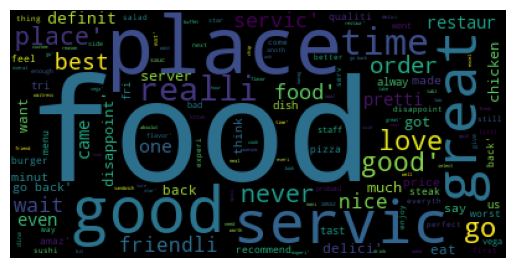

In [58]:
corp_str = str(corpus)
import matplotlib.pyplot as plt
from wordcloud import WordCloud
wordcloud = WordCloud(relative_scaling=1.0).generate(corp_str)
plt.imshow(wordcloud)
plt.axis("off")
plt.show()